## Nigeria Incidents Analysis Project

In [ ]:
# import libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [1]:
# load the dataset

In [2]:
df=pd.read_csv("Nigeria_Incidents_Project/data/incidents.csv")

In [3]:
df.head(5)

,Identifier,Title,Start date,End date,Number of deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1


In [4]:
df.shape

(7500, 5)

In [64]:
# Check the columns

In [6]:
df.columns

Index(['Identifier', 'Title', 'Start date', 'End date', 'Number of deaths'], dtype='object')

In [8]:
df.dtypes

Identifier          object
Title               object
Start date          object
End date            object
Number of deaths     int64
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Identifier        7500 non-null   object
 1   Title             7500 non-null   object
 2   Start date        7500 non-null   object
 3   End date          7500 non-null   object
 4   Number of deaths  7500 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 293.1+ KB


In [65]:
# Check missing values

In [11]:
df.isnull().sum()

Identifier          0
Title               0
Start date          0
End date            0
Number of deaths    0
dtype: int64

In [66]:
# Check duplicate rows

In [12]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
7495    False
7496    False
7497    False
7498    False
7499    False
Length: 7500, dtype: bool

In [13]:
df.duplicated().sum()

np.int64(15)

In [67]:
# Remove duplicates

In [15]:
df=df.drop_duplicates()

In [68]:
# then verify

In [16]:
df.duplicated().sum()

np.int64(0)

In [69]:
# Check the new dataset size:

In [17]:
df.shape

(7485, 5)

In [70]:
# Check data types

In [18]:
df.dtypes

Identifier          object
Title               object
Start date          object
End date            object
Number of deaths     int64
dtype: object

In [71]:
# Check invalid Start dates

In [21]:
df["Start date"] = pd.to_datetime(df["Start date"])

ValueError: time data "2023-00-20" doesn't match format "%Y-%m-%d", at position 820. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [23]:
pd.to_datetime(df["Start date"], errors="coerce").isna().sum()

np.int64(1)

In [72]:
# to see it

In [25]:
df.loc[df["Start date"] == "2023-00-20"]

,Identifier,Title,Start date,End date,Number of deaths
5842,IBD028043,"Police Kill Kidnapper, Yobe",2023-00-20,2023-00-20,1


In [26]:
pd.to_datetime(df["Start date"], errors="coerce").isna().sum()

np.int64(1)

In [73]:
# Check invalid End dates

In [29]:
# Convert dates
# Because there were invalid dates, we used errors="coerce"
# The invalid dates become NaT rather than causing an error.

In [30]:
df.dtypes

Identifier                  object
Title                       object
Start date          datetime64[ns]
End date            datetime64[ns]
Number of deaths             int64
dtype: object

In [31]:
df.loc[df["Start date"].isna()]

,Identifier,Title,Start date,End date,Number of deaths
5842,IBD028043,"Police Kill Kidnapper, Yobe",NaT,NaT,1


In [74]:
# Check Number of Deaths

In [78]:
df["Number of deaths"].describe()

count    7485.000000
mean        4.711824
std        11.165974
min         1.000000
25%         1.000000
50%         1.000000
75%         4.000000
max       244.000000
Name: Number of deaths, dtype: float64

In [75]:
# Check negative values

In [79]:
(df["Number of deaths"] < 0).sum()

np.int64(0)

In [76]:
# Check missing values

In [80]:
df["Number of deaths"].isnull().sum()

np.int64(0)

In [77]:
# Inspect the incident titles

In [81]:
df["Title"].head(20)

0                                 Food Poisoning, Imo
1                              Gunmen Kill Man, Benue
2                                   Auto Crash, Lagos
3                               Stray Bullets, Sokoto
4                     Lightening Kills Herder, Kaduna
5                                 Auto Crash, Katsina
6               Sallah Day Celebration Clash, Plateau
7                                    Auto Crash, Abia
8                                Gas Explosion, Delta
9                                    Auto Crash, Ogun
10                                    Stampede, Gombe
11                           Fishing Activities, Kogi
12                Herdsmen Kill Graduate, FCT (Abuja)
13                      Labourer Kills Employer, Ondo
14                                  Auto Crash, Lagos
15                       Extrajudicial Killing, Delta
16    Security Forces vs Shiites Members, FCT (Abuja)
17     Pirates vs Fashion Designer, Rivers (Offshore)
18                          

In [82]:
# create year

In [41]:
df["Year"] = df["Start date"].dt.year

In [83]:
# Create Month

In [42]:
df["Month"] = df["Start date"].dt.month

In [84]:
# Create Incident Duration

In [43]:
df["Incident Duration"] = (df["End date"] - df["Start date"]).dt.days

In [44]:
df.head()

,Identifier,Title,Start date,End date,Number of deaths,Year,Month,Incident Duration
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,2025.0,4.0,0.0
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,2025.0,3.0,0.0
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,2025.0,3.0,0.0
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,2025.0,3.0,0.0
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,2025.0,3.0,0.0


In [45]:
df[["Start date", "End date", "Year", "Month", "Incident Duration"]].head(10)

,Start date,End date,Year,Month,Incident Duration
0,2025-04-18,2025-04-18,2025.0,4.0,0.0
1,2025-03-31,2025-03-31,2025.0,3.0,0.0
2,2025-03-31,2025-03-31,2025.0,3.0,0.0
3,2025-03-31,2025-03-31,2025.0,3.0,0.0
4,2025-03-30,2025-03-30,2025.0,3.0,0.0
5,2025-03-30,2025-03-30,2025.0,3.0,0.0
6,2025-03-30,2025-03-30,2025.0,3.0,0.0
7,2025-03-30,2025-03-30,2025.0,3.0,0.0
8,2025-03-30,2025-03-30,2025.0,3.0,0.0
9,2025-03-30,2025-03-30,2025.0,3.0,0.0


## Research Question

In [85]:
# Incidents by year

In [47]:
incidents_by_year = df["Year"].value_counts().sort_index()
incidents_by_year

Year
2022.0    1653
2023.0    2604
2024.0    2610
2025.0     617
Name: count, dtype: int64

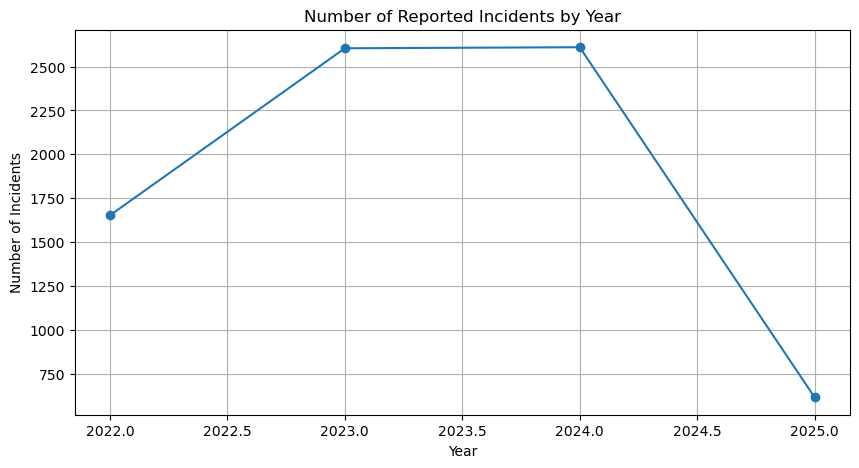

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(
    incidents_by_year.index,
    incidents_by_year.values,
    marker="o"
)

plt.title("Number of Reported Incidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Incidents")

plt.grid(True)

plt.show()

In [86]:
# Top 10 incidents by deaths

In [48]:
top_10_deaths = df.nlargest(10, "Number of deaths")[["Title", "Number of deaths"]]

top_10_deaths

,Title,Number of deaths
5433,"Herdsmen Attack, Benue",244
2317,"Heat Waves, Adamawa",210
2817,"Banditry, Katsina",200
5438,"ISWAP vs Boko Haram, Borno",200
6859,"Army vs Boko Haram, Borno",200
1046,"Petrol Tanker Explosion, Jigawa",186
1146,"Boat Mishap, Niger",180
2223,"Banditry, Zamfara",150
5940,"Banditry, Zamfara",130
3396,"Army Bombs Villagers, Kaduna",127


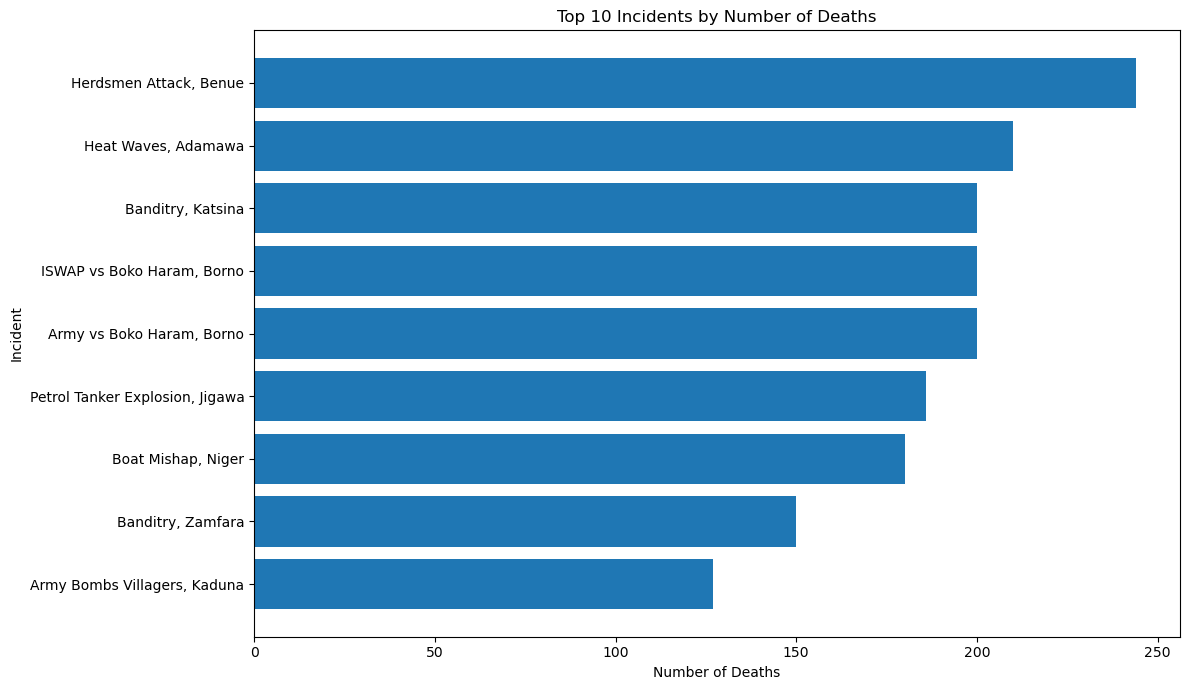

In [60]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_deaths["Title"],
    top_10_deaths["Number of deaths"]
)

plt.title("Top 10 Incidents by Number of Deaths")
plt.xlabel("Number of Deaths")
plt.ylabel("Incident")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [87]:
# Distribution of deaths

In [90]:
df["Number of deaths"].value_counts().sort_index().head(20)

Number of deaths
1     3836
2     1096
3      655
4      336
5      270
6      183
7      123
8       99
9       60
10     130
11      60
12      45
13      35
14      28
15      36
16      24
17      26
18      23
19      18
20      63
Name: count, dtype: int64

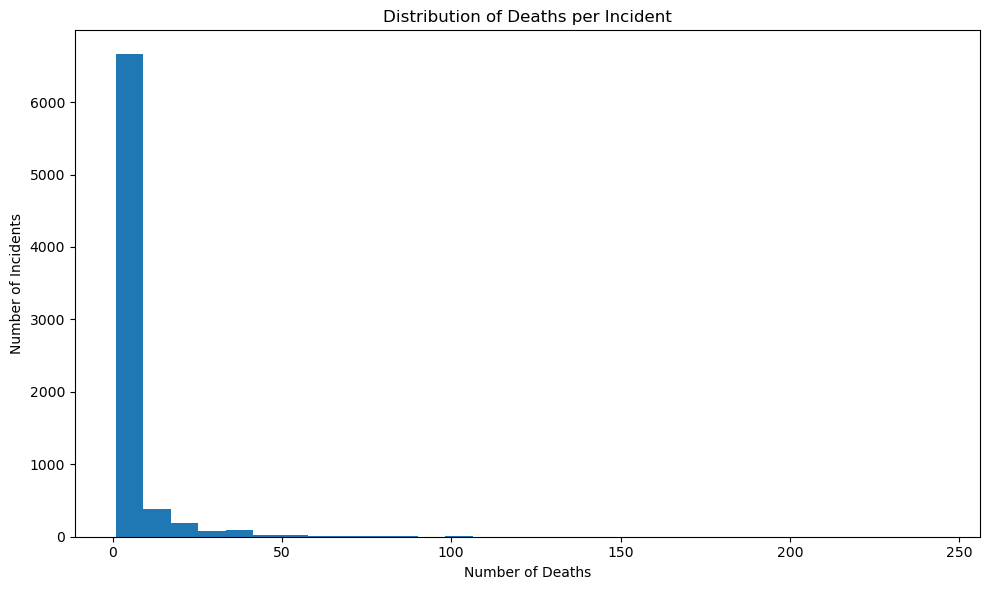

In [91]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Number of deaths"],
    bins=30
)

plt.title("Distribution of Deaths per Incident")
plt.xlabel("Number of Deaths")
plt.ylabel("Number of Incidents")

plt.tight_layout()

plt.show()

In [50]:
df["Incident Duration"].describe()

count    7484.000000
mean        0.640967
std        11.968645
min      -366.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       352.000000
Name: Incident Duration, dtype: float64

In [88]:
# Duration vs deaths

In [51]:
df[["Incident Duration", "Number of deaths"]].corr()

,Incident Duration,Number of deaths
Incident Duration,1.000000,0.038453
Number of deaths,0.038453,1.000000


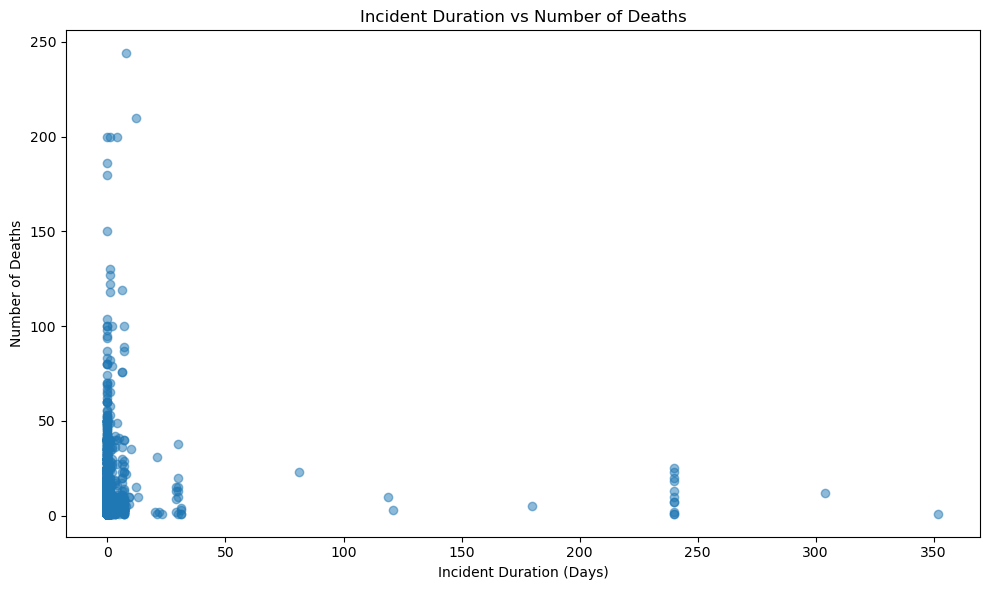

In [62]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Incident Duration"],
    df["Number of deaths"],
    alpha=0.5
)

plt.title("Incident Duration vs Number of Deaths")
plt.xlabel("Incident Duration (Days)")
plt.ylabel("Number of Deaths")

plt.tight_layout()
plt.show()

## Here i filtered the dataset to find incidents with negative durations, inspected their dates and other details to identify the data errors, and then handled those invalid durations by replacing them with missing values (NaN).

In [52]:
df[df["Incident Duration"] < 0][
    ["Identifier", "Title", "Start date", "End date", "Incident Duration", "Number of deaths"]
].head(20)

,Identifier,Title,Start date,End date,Incident Duration,Number of deaths
2136,IBD028052,"Auto Crash, Abia",2024-05-23,2023-05-23,-366.0,4
2836,IBD029365,"Kidnap Victims, Imo",2024-03-01,2024-02-01,-29.0,5
3422,IBD028563,"Assailants vs Lady, Lagos",2023-12-01,2023-11-01,-30.0,1
4084,IBD027910,"Troops Kill kidnappers, Plateau",2023-08-28,2023-08-04,-24.0,1
4261,IBD027680,"Cult Killing, Lagos",2023-08-01,2023-07-01,-31.0,1
4709,IBD027203,"Student vs Host Community, Ogun",2023-05-29,2023-05-28,-1.0,1
7336,IBD024913,"Cult Killing, Lagos",2022-07-07,2022-07-01,-6.0,2


In [53]:
(df["Incident Duration"] < 0).sum()

np.int64(7)

In [54]:
df.loc[df["Incident Duration"] < 0, "Incident Duration"] = np.nan

In [55]:
(df["Incident Duration"] < 0).sum()

np.int64(0)

In [56]:
df["Incident Duration"].isnull().sum()

np.int64(8)

In [57]:
df[["Incident Duration", "Number of deaths"]].corr()

,Incident Duration,Number of deaths
Incident Duration,1.000000,0.040553
Number of deaths,0.040553,1.000000


In [89]:
# Incidents by month

In [58]:
incidents_by_month = df["Month"].value_counts().sort_index()
incidents_by_month

Month
1.0     676
2.0     553
3.0     663
4.0     539
5.0     472
6.0     570
7.0     683
8.0     733
9.0     727
10.0    679
11.0    629
12.0    560
Name: count, dtype: int64

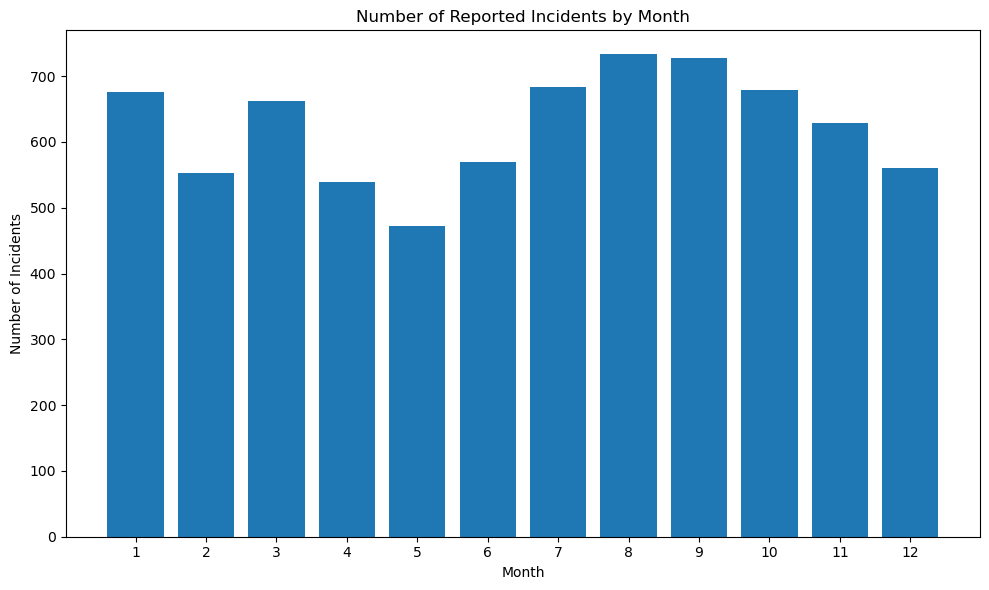

In [63]:
plt.figure(figsize=(10, 6))

plt.bar(
    incidents_by_month.index,
    incidents_by_month.values
)

plt.title("Number of Reported Incidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

## FINDINGS

## RECCOMMENDATION